# Comparative Analysis of CNN, RNN, and Hybrid CNN–RNN Architectures for Papilledema Detection and Severity Grading

## Section 1 — Research Overview

- **Objectives**: Benchmark CNN (`ResNet-50`, `DenseNet-121`, `EfficientNet-B0`), standalone RNN (`LSTM`, `BiLSTM`), Hybrid CNN–RNN (`ResNet-50 + LSTM`, `ResNet-50 + BiLSTM`, `EfficientNet-B0 + BiLSTM`), and Baseline (`MLP`, `Autoencoder + Classifier`) architectures using a unified, leakage-aware PyTorch pipeline.
- **Independent Experimental Tracks** (never merged into a single ranking table; no multimodal fusion claimed):
  1. **Kim Fundus Classification** (`Normal`, `Papilledema`, `Pseudopapilledema`) — primary architecture benchmark.
  2. **Original OCT 3-Class Classification** (`Normal`, `Papilledema`, `Pseudopapilledema`) — individual B-scan & ordered B-scan sequence tracks.
  3. **Original OCT Severity Classification** (`G1`, `G2`, `G3`, `G4`) — strictly exploratory.
- **Key Dataset Limitations**:
  - Verified patient IDs are unavailable for Kim Fundus; near-duplicate/repeated-eye clusters are grouped intact across splits, and conflicting cross-class exact duplicates are excluded.
  - Original OCT excludes 1 IR/SLO non-B-scan (`heshama_001.jpg`, leaving 1,140 B-scans) and all forbidden clones/augmented/fabricated-ID folders.
  - OCT sequence IDs are inferred from filenames; Normal (`sabrenr`), Pseudopapilledema (`heshama`), G1 (`hagerh`), and G4 (`mostafaa`) each have only 1 inferred subject prefix, precluding patient-independent generalization claims.


In [1]:
import os
import sys
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image as IPyImage, Markdown

# Resolve project root cleanly whether launched from root or notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_all_configs, get_hardware_info, get_device, seed_everything
from src.data import (
    run_full_data_verification,
    build_and_save_all_splits,
    load_split_df,
    create_dataloaders,
    FUNDUS_CLASSES,
    OCT_3CLASSES,
    OCT_SEVERITY_CLASSES,
)
from src.models import SUPPORTED_MODELS, build_model, count_parameters
from src.training import run_single_experiment, run_experiment_suite
from src.experiments import ExperimentManager

cfg = load_all_configs()
print(f"Project root: {PROJECT_ROOT}")


Project root: C:\Users\Shuvendu\Desktop\Papilledema_analysis


## Section 2 — Hardware Verification


In [2]:
hw = get_hardware_info()
display(pd.DataFrame([{k: v for k, v in hw.items() if k != "dependencies"}]).T.rename(columns={0: "Value"}))
print("Dependencies:", json.dumps(hw["dependencies"], indent=2))
if hw["cuda_available"] and not hw["gpu_compatible"]:
    raise RuntimeError(f"Incompatible GPU/PyTorch build: {hw['gpu_status']}")


,Value
python_version,3.12.10
platform,Windows-11-10.0.26200-SP0
cpu,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
cpu_cores_physical,10
cpu_cores_logical,16
ram_total_gb,23.64
torch_version,2.14.0+cu132
cuda_available,True
cuda_version,13.2
gpu_compatible,True


Dependencies: {
  "torchvision": "0.29.0+cu132",
  "numpy": "2.5.2",
  "pandas": "3.0.5",
  "sklearn": "1.9.0",
  "scipy": "1.18.1",
  "matplotlib": "3.11.1",
  "seaborn": "0.13.2",
  "PIL": "12.3.0",
  "cv2": "5.0.0",
  "albumentations": "2.0.8",
  "yaml": "6.0.3",
  "tqdm": "4.70.0"
}


## Section 3 — Dataset Validation & Sample Inspection


In [3]:
audit = run_full_data_verification(cfg)
split_report = build_and_save_all_splits(cfg, seed=cfg["project"]["default_seed"], force_verify=False)

print("=== Fundus Audit ===")
print(json.dumps(audit["fundus"], indent=2))
print("\n=== OCT Audit ===")
print(json.dumps(audit["oct"], indent=2))
print("\n=== Split Leakage Check ===")
for tname, rep in split_report.items():
    if isinstance(rep, dict):
        print(f"{tname}: passed={rep['passed']} | splits={rep['split_counts']} | warnings={rep['warnings']}")

# Display sample Fundus and OCT images
import matplotlib.pyplot as plt
from PIL import Image

f_df = load_split_df(cfg, "fundus_3class")
o_df = load_split_df(cfg, "oct_3class")

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for j, cls in enumerate(FUNDUS_CLASSES):
    p = f_df[f_df["label"] == cls]["image_path"].iloc[0]
    axes[0, j].imshow(Image.open(p).convert("RGB"))
    axes[0, j].set_title(f"Fundus: {cls}")
    axes[0, j].axis("off")
for j, cls in enumerate(OCT_3CLASSES):
    p = o_df[o_df["label"] == cls]["image_path"].iloc[0]
    axes[1, j].imshow(Image.open(p).convert("L"), cmap="gray")
    axes[1, j].set_title(f"OCT: {cls}")
    axes[1, j].axis("off")
plt.tight_layout()
plt.show()


=== Fundus Audit ===
{
  "raw_total": 1369,
  "corrupted_count": 0,
  "excluded_cross_class_count": 2,
  "retained_total": 1367,
  "retained_class_counts": {
    "Normal": 778,
    "Papilledema": 295,
    "Pseudopapilledema": 294
  },
  "raw_class_counts": {
    "Normal": 779,
    "Papilledema": 295,
    "Pseudopapilledema": 295
  },
  "unique_clusters": 1270,
  "multi_image_clusters": 74,
  "images_in_multi_clusters": 171,
  "near_dup_pairs": 110,
  "cross_class_conflicts": 1,
  "dimensions": {
    "240x240": 1365,
    "240x208": 1,
    "240x225": 1
  }
}

=== OCT Audit ===
{
  "raw_total_scanned": 1141,
  "excluded_count": 1,
  "excluded_files": [
    {
      "image_path": "data/raw/OCT/Original Data/OCT/Pseudo papilledema/heshama_001.jpg",
      "folder_class": "Pseudopapilledema",
      "exclusion_reason": "IR/SLO reflectance image detected (size=(269,701), max_ch_diff=0)"
    }
  ],
  "retained_bscan_total": 1140,
  "class_3_counts": {
    "Papilledema": 895,
    "Normal": 132,
  

C:\Users\Shuvendu\AppData\Local\Temp\ipykernel_21260\1659416448.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Section 4 — Experiment Configuration


In [4]:
RUN_ALL_MODELS = True

RUN_FUNDUS = True
RUN_OCT = True
RUN_SEVERITY = True

RUN_SMOKE_TESTS = True
RUN_STATISTICAL_ANALYSIS = True

USE_MULTIPLE_SEEDS = True
NUM_SEEDS = 5

EPOCHS = 30
BATCH_SIZE = 16
IMAGE_SIZE = 224

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

USE_MIXED_PRECISION = True
EARLY_STOPPING_PATIENCE = 7

# Set True (or env PAPI_SMOKE_ONLY=1) for a fast 1-epoch verification pass across the notebook
SMOKE_TEST_ONLY = os.environ.get("PAPI_SMOKE_ONLY", "0") == "1"

# Individual model toggles
ENABLED_MODELS = {m: RUN_ALL_MODELS for m in SUPPORTED_MODELS}
SEEDS = (
    [int(cfg["project"]["default_seed"])]
    if (SMOKE_TEST_ONLY or not USE_MULTIPLE_SEEDS)
    else list(cfg["project"]["random_seeds"])[:NUM_SEEDS]
)
EFF_EPOCHS = 1 if SMOKE_TEST_ONLY else EPOCHS
RUN_TAG = "smoke" if SMOKE_TEST_ONLY else ""

print(f"SMOKE_TEST_ONLY={SMOKE_TEST_ONLY} | EFF_EPOCHS={EFF_EPOCHS} | SEEDS={SEEDS}")


SMOKE_TEST_ONLY=False | EFF_EPOCHS=30 | SEEDS=[42, 123, 2024, 3407, 5678]


## Section 5 — Smoke Tests


In [5]:
import torch

if RUN_SMOKE_TESTS:
    seed_everything(42)
    device = get_device(prefer_gpu=True)
    # 1. Verify DataLoaders + Forward/Loss/Backward across all 10 architectures on synthetic/real mini-batches
    loaders_f, _ = create_dataloaders(cfg, "fundus_3class", mode="image", batch_size=4, image_size=IMAGE_SIZE)
    bx, by = next(iter(loaders_f["train"]))
    bx, by = bx.to(device), by.to(device)

    for mname in SUPPORTED_MODELS:
        m = build_model(mname, num_classes=3, in_channels=3, image_size=IMAGE_SIZE, cfg=cfg, pretrained=False).to(device)
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1e-4)
        logits = m(bx)
        loss = torch.nn.CrossEntropyLoss()(logits, by)
        opt.zero_grad()
        loss.backward()
        opt.step()
        assert logits.shape == (bx.size(0), 3), f"Shape mismatch for {mname}"
        del m, opt, logits, loss

    # 2. Verify 5D OCT sequence forward + backward
    loaders_seq, _ = create_dataloaders(cfg, "oct_3class", mode="sequence", batch_size=2, image_size=IMAGE_SIZE)
    (sx, smask), sy = next(iter(loaders_seq["train"]))
    sx, smask, sy = sx.to(device), smask.to(device), sy.to(device)
    hm = build_model("resnet50_bilstm", num_classes=3, in_channels=1, image_size=IMAGE_SIZE, cfg=cfg, pretrained=False).to(device)
    out = hm((sx, smask))
    torch.nn.CrossEntropyLoss()(out, sy).backward()
    del hm, out

    # 3. Verify 1-epoch checkpointed smoke training + evaluation end-to-end
    smoke_eval = run_single_experiment(
        cfg, track="fundus_3class", model_name="mlp", seed=42,
        epochs=1, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
        use_mixed_precision=USE_MIXED_PRECISION, is_smoke=True, tag="smoke",
    )
    print("All smoke tests passed! Smoke MLP macro_f1:", smoke_eval["metrics"]["macro_f1"])


All smoke tests passed! Smoke MLP macro_f1: 0.347637


## Section 6 — Fundus CNN Training


In [6]:
if RUN_FUNDUS:
    cnn_models = [m for m in ("resnet50", "densenet121", "efficientnet_b0") if ENABLED_MODELS.get(m, False)]
    if SMOKE_TEST_ONLY:
        cnn_models = cnn_models[:1]
    if cnn_models:
        run_experiment_suite(
            cfg, track="fundus_3class", models=cnn_models, seeds=SEEDS,
            epochs=EFF_EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
            lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
            use_mixed_precision=USE_MIXED_PRECISION, early_stopping_patience=EARLY_STOPPING_PATIENCE,
            is_smoke=SMOKE_TEST_ONLY, tag=RUN_TAG,
        )


## Section 7 — Fundus Standalone RNN Training


In [7]:
if RUN_FUNDUS:
    rnn_models = [m for m in ("lstm", "bilstm") if ENABLED_MODELS.get(m, False)]
    if SMOKE_TEST_ONLY:
        rnn_models = rnn_models[:1]
    if rnn_models:
        run_experiment_suite(
            cfg, track="fundus_3class", models=rnn_models, seeds=SEEDS,
            epochs=EFF_EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
            lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
            use_mixed_precision=USE_MIXED_PRECISION, early_stopping_patience=EARLY_STOPPING_PATIENCE,
            is_smoke=SMOKE_TEST_ONLY, tag=RUN_TAG,
        )


## Section 8 — Fundus Hybrid CNN–RNN Training


In [8]:
if RUN_FUNDUS:
    hybrid_models = [m for m in ("resnet50_lstm", "resnet50_bilstm", "efficientnet_b0_bilstm") if ENABLED_MODELS.get(m, False)]
    if SMOKE_TEST_ONLY:
        hybrid_models = hybrid_models[:1]
    if hybrid_models:
        run_experiment_suite(
            cfg, track="fundus_3class", models=hybrid_models, seeds=SEEDS,
            epochs=EFF_EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
            lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
            use_mixed_precision=USE_MIXED_PRECISION, early_stopping_patience=EARLY_STOPPING_PATIENCE,
            is_smoke=SMOKE_TEST_ONLY, tag=RUN_TAG,
        )


## Section 9 — Fundus Baselines


In [9]:
if RUN_FUNDUS:
    base_models = [m for m in ("mlp", "autoencoder_classifier") if ENABLED_MODELS.get(m, False)]
    if base_models:
        run_experiment_suite(
            cfg, track="fundus_3class", models=base_models, seeds=SEEDS,
            epochs=EFF_EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
            lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
            use_mixed_precision=USE_MIXED_PRECISION, early_stopping_patience=EARLY_STOPPING_PATIENCE,
            is_smoke=SMOKE_TEST_ONLY, tag=RUN_TAG,
        )


## Section 10 — OCT Experiments (Individual B-Scan, Sequence, Exploratory Severity)


In [10]:
RUN_OCT_INDIVIDUAL = RUN_OCT
RUN_OCT_SEQUENCE = RUN_OCT
RUN_OCT_SEVERITY = RUN_SEVERITY

if RUN_OCT_INDIVIDUAL:
    m_ind = ["efficientnet_b0"] if SMOKE_TEST_ONLY else [m for m in cfg["experiments"]["oct_individual"]["models"] if ENABLED_MODELS.get(m, True)]
    run_experiment_suite(
        cfg, track="oct_individual", models=m_ind, seeds=SEEDS,
        epochs=EFF_EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
        lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
        use_mixed_precision=USE_MIXED_PRECISION, early_stopping_patience=EARLY_STOPPING_PATIENCE,
        is_smoke=SMOKE_TEST_ONLY, tag=RUN_TAG,
    )

if RUN_OCT_SEQUENCE:
    m_seq = ["resnet50_bilstm"] if SMOKE_TEST_ONLY else [m for m in cfg["experiments"]["oct_sequence"]["models"] if ENABLED_MODELS.get(m, True)]
    run_experiment_suite(
        cfg, track="oct_sequence", models=m_seq, seeds=SEEDS,
        epochs=EFF_EPOCHS, batch_size=4, image_size=IMAGE_SIZE,
        lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
        use_mixed_precision=USE_MIXED_PRECISION, early_stopping_patience=EARLY_STOPPING_PATIENCE,
        is_smoke=SMOKE_TEST_ONLY, tag=RUN_TAG,
    )

if RUN_OCT_SEVERITY:
    m_sev = ["efficientnet_b0"] if SMOKE_TEST_ONLY else [m for m in cfg["experiments"]["oct_severity"]["models"] if ENABLED_MODELS.get(m, True)]
    run_experiment_suite(
        cfg, track="oct_severity", models=m_sev, seeds=SEEDS,
        epochs=EFF_EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
        lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
        use_mixed_precision=USE_MIXED_PRECISION, early_stopping_patience=EARLY_STOPPING_PATIENCE,
        is_smoke=SMOKE_TEST_ONLY, tag=RUN_TAG,
    )


## Section 11 — Evaluation & Automated Output Generation


In [11]:
mgr = ExperimentManager(cfg)
gen_summary = mgr.generate_all_outputs()
runs_df = mgr.collect_completed_runs()
if not runs_df.empty and (~runs_df["is_smoke"]).any():
    runs_df = runs_df[~runs_df["is_smoke"]].reset_index(drop=True)
display(runs_df[["exp_id", "track", "model", "seed", "accuracy", "macro_f1", "macro_recall", "roc_auc_ovr", "total_params", "inference_latency_ms"]])


,exp_id,track,model,seed,accuracy,macro_f1,macro_recall,roc_auc_ovr,total_params,inference_latency_ms
0,fundus_3class__autoencoder_classifier__seed123,fundus_3class,autoencoder_classifier,123,0.887805,0.858423,0.849391,0.965064,718118,1.7421
1,fundus_3class__autoencoder_classifier__seed2024,fundus_3class,autoencoder_classifier,2024,0.892683,0.868480,0.871147,0.959342,718118,1.7265
2,fundus_3class__autoencoder_classifier__seed3407,fundus_3class,autoencoder_classifier,3407,0.892683,0.864353,0.861694,0.964022,718118,1.7187
3,fundus_3class__autoencoder_classifier__seed42,fundus_3class,autoencoder_classifier,42,0.907317,0.887018,0.884421,0.968602,718118,1.7392
4,fundus_3class__autoencoder_classifier__seed5678,fundus_3class,autoencoder_classifier,5678,0.887805,0.867106,0.863572,0.962696,718118,1.6952
...,...,...,...,...,...,...,...,...,...,...
170,oct_severity__resnet50_lstm__seed123,oct_severity,resnet50_lstm,123,0.869318,0.539780,0.540246,0.924910,24241604,3.6526
171,oct_severity__resnet50_lstm__seed2024,oct_severity,resnet50_lstm,2024,0.607955,0.455235,0.464975,0.666014,24241604,3.7814
172,oct_severity__resnet50_lstm__seed3407,oct_severity,resnet50_lstm,3407,0.892045,0.653774,0.610140,0.859265,24241604,4.0083
173,oct_severity__resnet50_lstm__seed42,oct_severity,resnet50_lstm,42,0.647727,0.474383,0.476961,0.701737,24241604,3.8374


## Section 12 — Statistical Analysis


In [12]:
if RUN_STATISTICAL_ANALYSIS:
    stat_dir = Path(cfg["paths"]["results_dir"]) / "statistical_analysis"
    for fname in ("descriptive_statistics.csv", "confidence_intervals.csv", "hypothesis_tests.csv", "pairwise_comparisons.csv", "effect_sizes.csv"):
        fpath = stat_dir / fname
        if fpath.exists() and fpath.stat().st_size > 2:
            print(f"=== {fname} ===")
            display(pd.read_csv(fpath).head(15))


=== descriptive_statistics.csv ===


,track,model,metric,n,mean,std,median,min,max,iqr,ci95_low,ci95_high,note
0,fundus_3class,autoencoder_classifier,macro_f1,5,0.869076,0.010746,0.867106,0.858423,0.887018,0.004127,0.855733,0.882419,Seed variance on fixed split; NOT independent ...
1,fundus_3class,autoencoder_classifier,accuracy,5,0.893659,0.008015,0.892683,0.887805,0.907317,0.004878,0.883706,0.903611,Seed variance on fixed split; NOT independent ...
2,fundus_3class,autoencoder_classifier,balanced_accuracy,5,0.866045,0.012905,0.863572,0.849391,0.884421,0.009453,0.850022,0.882068,Seed variance on fixed split; NOT independent ...
3,fundus_3class,autoencoder_classifier,macro_precision,5,0.873458,0.010641,0.868729,0.866748,0.892303,0.002446,0.860246,0.886671,Seed variance on fixed split; NOT independent ...
4,fundus_3class,autoencoder_classifier,macro_recall,5,0.866045,0.012905,0.863572,0.849391,0.884421,0.009453,0.850022,0.882068,Seed variance on fixed split; NOT independent ...
5,fundus_3class,autoencoder_classifier,weighted_precision,5,0.892824,0.008241,0.891409,0.886286,0.906714,0.005711,0.882592,0.903056,Seed variance on fixed split; NOT independent ...
6,fundus_3class,autoencoder_classifier,weighted_recall,5,0.893659,0.008015,0.892683,0.887805,0.907317,0.004878,0.883706,0.903611,Seed variance on fixed split; NOT independent ...
7,fundus_3class,autoencoder_classifier,weighted_f1,5,0.892761,0.007902,0.891532,0.886489,0.906126,0.005120,0.882949,0.902573,Seed variance on fixed split; NOT independent ...
8,fundus_3class,autoencoder_classifier,roc_auc_ovr,5,0.963945,0.003380,0.964022,0.959342,0.968602,0.002368,0.959749,0.968142,Seed variance on fixed split; NOT independent ...
9,fundus_3class,autoencoder_classifier,pr_auc_ovr,5,0.923296,0.012056,0.925610,0.904169,0.936546,0.007518,0.908327,0.938265,Seed variance on fixed split; NOT independent ...


=== confidence_intervals.csv ===


,track,model,exp_id,metric,point_estimate,ci95_low,ci95_high,n_samples,n_groups,n_resamples,warning
0,fundus_3class,autoencoder_classifier,fundus_3class__autoencoder_classifier__seed5678,accuracy,0.887805,0.839604,0.930000,205,190,2000,Grouped resampling over 190 clusters/sequences...
1,fundus_3class,autoencoder_classifier,fundus_3class__autoencoder_classifier__seed5678,balanced_accuracy,0.863572,0.801720,0.916371,205,190,2000,Grouped resampling over 190 clusters/sequences...
2,fundus_3class,autoencoder_classifier,fundus_3class__autoencoder_classifier__seed5678,macro_f1,0.867106,0.808108,0.916533,205,190,2000,Grouped resampling over 190 clusters/sequences...
3,fundus_3class,autoencoder_classifier,fundus_3class__autoencoder_classifier__seed5678,macro_precision,0.870979,0.811284,0.922348,205,190,2000,Grouped resampling over 190 clusters/sequences...
4,fundus_3class,autoencoder_classifier,fundus_3class__autoencoder_classifier__seed5678,macro_recall,0.863572,0.801720,0.916371,205,190,2000,Grouped resampling over 190 clusters/sequences...
5,fundus_3class,autoencoder_classifier,fundus_3class__autoencoder_classifier__seed5678,weighted_f1,0.887269,0.837674,0.929188,205,190,2000,Grouped resampling over 190 clusters/sequences...
6,fundus_3class,bilstm,fundus_3class__bilstm__seed123,accuracy,0.780488,0.716418,0.837438,205,190,2000,Grouped resampling over 190 clusters/sequences...
7,fundus_3class,bilstm,fundus_3class__bilstm__seed123,balanced_accuracy,0.777260,0.701553,0.840386,205,190,2000,Grouped resampling over 190 clusters/sequences...
8,fundus_3class,bilstm,fundus_3class__bilstm__seed123,macro_f1,0.750653,0.678112,0.815460,205,190,2000,Grouped resampling over 190 clusters/sequences...
9,fundus_3class,bilstm,fundus_3class__bilstm__seed123,macro_precision,0.736621,0.668800,0.803856,205,190,2000,Grouped resampling over 190 clusters/sequences...


=== hypothesis_tests.csv ===


,track,models_compared,metric,test_used,statistic,p_value,p_adjusted,effect_size_name,effect_size,significant,n_matched_seeds,sample_size,null_hypothesis,alternative_hypothesis,assumptions,interpretation,notes
0,fundus_3class,"autoencoder_classifier, bilstm, densenet121, e...",macro_f1,Friedman test,38.252734,0.000016,0.000016,kendalls_w,0.850061,True,5.0,5 seeds x 10 models,All 10 architectures share the same median mac...,At least one architecture differs in macro_f1 ...,Matched blocks across random seeds on fixed sp...,"Reject H0 after global test (W=0.850, p=0.0000...",Matched across random seeds on fixed split (no...
1,fundus_3class,autoencoder_classifier vs bilstm,test_accuracy_errors,McNemar (chi2 continuity-corrected),14.700000,0.000126,0.002773,cohens_g,0.366667,True,NaN,205 test items (190 groups),autoencoder_classifier and bilstm have equal e...,autoencoder_classifier and bilstm have differe...,Paired test items with independent errors (bes...,"Reject H0 (b=26 vs c=4 discordant errors, Holm...",Discordant count=30. Assumes test sample error...
2,fundus_3class,autoencoder_classifier vs densenet121,test_accuracy_errors,McNemar (exact binomial),1.000000,0.000011,0.000285,cohens_g,-0.454545,True,NaN,205 test items (190 groups),autoencoder_classifier and densenet121 have eq...,autoencoder_classifier and densenet121 have di...,Paired test items with independent errors (bes...,"Reject H0 (b=1 vs c=21 discordant errors, Holm...",Discordant count=22 (<25); exact binomial used.
3,fundus_3class,autoencoder_classifier vs efficientnet_b0,test_accuracy_errors,McNemar (chi2 continuity-corrected),12.960000,0.000318,0.006683,cohens_g,-0.380000,True,NaN,205 test items (190 groups),autoencoder_classifier and efficientnet_b0 hav...,autoencoder_classifier and efficientnet_b0 hav...,Paired test items with independent errors (bes...,"Reject H0 (b=3 vs c=22 discordant errors, Holm...",Discordant count=25. Assumes test sample error...
4,fundus_3class,autoencoder_classifier vs efficientnet_b0_bilstm,test_accuracy_errors,McNemar (exact binomial),1.000000,0.000006,0.000154,cohens_g,-0.456522,True,NaN,205 test items (190 groups),autoencoder_classifier and efficientnet_b0_bil...,autoencoder_classifier and efficientnet_b0_bil...,Paired test items with independent errors (bes...,"Reject H0 (b=1 vs c=22 discordant errors, Holm...",Discordant count=23 (<25); exact binomial used.
5,fundus_3class,autoencoder_classifier vs lstm,test_accuracy_errors,McNemar (chi2 continuity-corrected),12.000000,0.000532,0.010640,cohens_g,0.351852,True,NaN,205 test items (190 groups),autoencoder_classifier and lstm have equal err...,autoencoder_classifier and lstm have different...,Paired test items with independent errors (bes...,"Reject H0 (b=23 vs c=4 discordant errors, Holm...",Discordant count=27. Assumes test sample error...
6,fundus_3class,autoencoder_classifier vs mlp,test_accuracy_errors,McNemar (chi2 continuity-corrected),6.322581,0.011921,0.226499,cohens_g,0.241935,False,NaN,205 test items (190 groups),autoencoder_classifier and mlp have equal erro...,autoencoder_classifier and mlp have different ...,Paired test items with independent errors (bes...,"Fail to reject H0 (b=23 vs c=8, Holm p=0.2265).",Discordant count=31. Assumes test sample error...
7,fundus_3class,autoencoder_classifier vs resnet50,test_accuracy_errors,McNemar (exact binomial),2.000000,0.000036,0.000897,cohens_g,-0.416667,True,NaN,205 test items (190 groups),autoencoder_classifier and resnet50 have equal...,autoencoder_classifier and resnet50 have diffe...,Paired test items with independent errors (bes...,"Reject H0 (b=2 vs c=22 discordant errors, Holm...",Discordant count=24 (<25); exact binomial used.
8,fundus_3class,autoencoder_classifier vs resnet50_bilstm,test_accuracy_errors,McNemar (exact binomial),2.000000,0.000036,0.000897,cohens_g,-0.416667,True,NaN,205 test items (190 groups),autoencoder_classifier and resnet50_bilstm hav...,autoencoder_classifier and resnet50_bilstm hav...,Paired te

=== pairwise_comparisons.csv ===


,track,models_compared,model_a,model_b,metric,test_used,sample_size,statistic,p_value,p_adjusted,effect_size_name,effect_size,mean_diff,significant,null_hypothesis,alternative_hypothesis,assumptions,interpretation,notes
0,fundus_3class,autoencoder_classifier vs bilstm,autoencoder_classifier,bilstm,macro_f1,Paired t-test (seeds),5 matched seeds,6.592296,0.002743,0.054851,cohens_d,2.948164,0.146097,False,Mean paired seed difference in macro_f1 (autoe...,Mean paired seed difference in macro_f1 != 0.,Paired seed differences approximately normal o...,Fail to reject H0 after Holm correction.,n=5 matched seeds.
1,fundus_3class,autoencoder_classifier vs bilstm,autoencoder_classifier,bilstm,macro_f1,Wilcoxon signed-rank (seeds),5 matched seeds,0.000000,0.062500,1.000000,rank_biserial_r,1.000000,0.146097,False,Median paired seed difference in macro_f1 (aut...,Median paired seed difference in macro_f1 != 0.,Symmetric paired differences; min achievable t...,Fail to reject H0 (underpowered at n<=5 seeds).,Min achievable two-sided p at n_nonzero=5 (of ...
2,fundus_3class,autoencoder_classifier vs densenet121,autoencoder_classifier,densenet121,macro_f1,Paired t-test (seeds),5 matched seeds,-19.073044,0.000045,0.001501,cohens_d,-8.529725,-0.110413,True,Mean paired seed difference in macro_f1 (autoe...,Mean paired seed difference in macro_f1 != 0.,Paired seed differences approximately normal o...,Reject H0 (seed-level optimization diff).,n=5 matched seeds. Shapiro-Wilk p=0.003<0.05 (...
3,fundus_3class,autoencoder_classifier vs densenet121,autoencoder_classifier,densenet121,macro_f1,Wilcoxon signed-rank (seeds),5 matched seeds,0.000000,0.062500,1.000000,rank_biserial_r,-1.000000,-0.110413,False,Median paired seed difference in macro_f1 (aut...,Median paired seed difference in macro_f1 != 0.,Symmetric paired differences; min achievable t...,Fail to reject H0 (underpowered at n<=5 seeds).,Min achievable two-sided p at n_nonzero=5 (of ...
4,fundus_3class,autoencoder_classifier vs efficientnet_b0,autoencoder_classifier,efficientnet_b0,macro_f1,Paired t-test (seeds),5 matched seeds,-30.012479,0.000007,0.000294,cohens_d,-13.421989,-0.114473,True,Mean paired seed difference in macro_f1 (autoe...,Mean paired seed difference in macro_f1 != 0.,Paired seed differences approximately normal o...,Reject H0 (seed-level optimization diff).,n=5 matched seeds.
5,fundus_3class,autoencoder_classifier vs efficientnet_b0,autoencoder_classifier,efficientnet_b0,macro_f1,Wilcoxon signed-rank (seeds),5 matched seeds,0.000000,0.062500,1.000000,rank_biserial_r,-1.000000,-0.114473,False,Median paired seed difference in macro_f1 (aut...,Median paired seed difference in macro_f1 != 0.,Symmetric paired differences; min achievable t...,Fail to reject H0 (underpowered at n<=5 seeds).,Min achievable two-sided p at n_nonzero=5 (of ...
6,fundus_3class,autoencoder_classifier vs efficientnet_b0_bilstm,autoencoder_classifier,efficientnet_b0_bilstm,macro_f1,Paired t-test (seeds),5 matched seeds,-13.553822,0.000172,0.004802,cohens_d,-6.061453,-0.111554,True,Mean paired seed difference in macro_f1 (autoe...,Mean paired seed difference in macro_f1 != 0.,Paired seed differences approximately normal o...,Reject H0 (seed-level optimization diff).,n=5 matched seeds.
7,fundus_3class,autoencoder_classifier vs efficientnet_b0_bilstm,autoencoder_classifier,efficientnet_b0_bilstm,macro_f1,Wilcoxon signed-rank (seeds),5 matched seeds,0.000000,0.062500,1.000000,rank_biserial_r,-1.000000,-0.111554,False,Median paired seed difference in macro_f1 (aut...,Median paired seed difference in macro_f1 != 0.,Symmetric paired differences; min achievable t...,Fail to reject H0 (underpowered at n<=5 seeds).,Min achievable two-sided p at n_nonzero=5 (of ...
8,fundus_3class,autoencoder_classifier vs lstm,autoencoder_classifier,lstm,macro_f1,Paired t-test (seeds),5 matched seeds,11.909119,0.000285,0.007119,cohens_d,5.325920,0.116878,True,Mean paired seed difference in macro_f1 (autoe...,Mean paired seed differenc

=== effect_sizes.csv ===


,track,models_compared,metric,cohens_d,rank_biserial_r,mean_diff
0,fundus_3class,autoencoder_classifier vs bilstm,macro_f1,2.948164,1.0,0.146097
1,fundus_3class,autoencoder_classifier vs densenet121,macro_f1,-8.529725,-1.0,-0.110413
2,fundus_3class,autoencoder_classifier vs efficientnet_b0,macro_f1,-13.421989,-1.0,-0.114473
3,fundus_3class,autoencoder_classifier vs efficientnet_b0_bilstm,macro_f1,-6.061453,-1.0,-0.111554
4,fundus_3class,autoencoder_classifier vs lstm,macro_f1,5.325920,1.0,0.116878
5,fundus_3class,autoencoder_classifier vs mlp,macro_f1,2.814020,1.0,0.067302
6,fundus_3class,autoencoder_classifier vs resnet50,macro_f1,-8.190818,-1.0,-0.108868
7,fundus_3class,autoencoder_classifier vs resnet50_bilstm,macro_f1,-8.484874,-1.0,-0.108776
8,fundus_3class,autoencoder_classifier vs resnet50_lstm,macro_f1,-10.095408,-1.0,-0.099315
9,fundus_3class,bilstm vs densenet121,macro_f1,-4.936483,-1.0,-0.256510


## Section 13 — Separate Track & Model-Family Comparisons


In [13]:
tables_dir = Path(cfg["paths"]["results_dir"]) / "tables"
for tname in ("cnn_comparison.csv", "rnn_comparison.csv", "hybrid_comparison.csv", "model_comparison.csv", "oct_comparison.csv", "computational_comparison.csv"):
    tp = tables_dir / tname
    if tp.exists() and tp.stat().st_size > 2:
        print(f"=== {tname} ===")
        display(pd.read_csv(tp))


=== cnn_comparison.csv ===


,track,mode,category,model,runs,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,accuracy_mean,macro_precision_mean,macro_recall_mean,weighted_f1_mean,roc_auc_mean,pr_auc_mean,total_params,train_time_mean_sec,inference_latency_ms
0,fundus_3class,image,cnn,efficientnet_b0,5,0.983549,0.005512,0.981818,0.988293,0.986091,0.981818,0.988197,0.999802,0.999355,4011391,154.0624,2.54114
1,fundus_3class,image,cnn,densenet121,5,0.979489,0.005369,0.978594,0.984390,0.980492,0.978594,0.984360,0.999468,0.998339,6956931,159.5632,3.25200
2,fundus_3class,image,cnn,resnet50,5,0.977944,0.003407,0.977079,0.983415,0.979632,0.977079,0.983366,0.996792,0.994296,23514179,121.0832,3.10458


=== rnn_comparison.csv ===


,track,mode,category,model,runs,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,accuracy_mean,macro_precision_mean,macro_recall_mean,weighted_f1_mean,roc_auc_mean,pr_auc_mean,total_params,train_time_mean_sec,inference_latency_ms
0,fundus_3class,image,rnn,lstm,5,0.752198,0.013223,0.772715,0.777561,0.745486,0.772715,0.783527,0.907274,0.790034,720899,153.4530,2.2763
1,fundus_3class,image,rnn,bilstm,5,0.722979,0.047970,0.745610,0.752195,0.711162,0.745610,0.757866,0.884050,0.744731,1116803,179.7348,2.7825


=== hybrid_comparison.csv ===


,track,mode,category,model,runs,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,accuracy_mean,macro_precision_mean,macro_recall_mean,weighted_f1_mean,roc_auc_mean,pr_auc_mean,total_params,train_time_mean_sec,inference_latency_ms
0,fundus_3class,image,hybrid,efficientnet_b0_bilstm,5,0.980630,0.010006,0.981999,0.985366,0.979534,0.981999,0.985388,0.998561,0.995702,4748927,116.7224,2.56606
1,fundus_3class,image,hybrid,resnet50_bilstm,5,0.977852,0.008544,0.976133,0.983415,0.979960,0.976133,0.983312,0.996360,0.994003,24446019,138.3012,3.09036
2,fundus_3class,image,hybrid,resnet50_lstm,5,0.968391,0.008446,0.968363,0.976586,0.969459,0.968363,0.976601,0.995338,0.991009,24247747,124.5128,3.02258


... (2 outputs left out)

=== oct_comparison.csv ===


,track,mode,category,model,runs,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,accuracy_mean,macro_precision_mean,macro_recall_mean,weighted_f1_mean,roc_auc_mean,pr_auc_mean,total_params,train_time_mean_sec,inference_latency_ms
0,oct_individual,image,cnn,densenet121,5,0.992772,0.009898,0.993333,0.997814,0.992592,0.993333,0.997818,1.000000,1.000000,6950659,60.2958,3.88988
1,oct_individual,image,cnn,efficientnet_b0,5,0.990315,0.000000,0.983333,0.994536,0.997732,0.983333,0.994475,0.999652,0.998476,4010815,53.6516,3.25330
2,oct_individual,image,hybrid,resnet50_bilstm,5,0.986339,0.025480,0.985753,0.993443,0.988633,0.985753,0.993431,0.999651,0.999616,24439747,68.7380,3.87442
3,oct_individual,image,hybrid,efficientnet_b0_bilstm,5,0.980679,0.015449,0.981963,0.991257,0.980891,0.981963,0.991291,0.999594,0.998440,4748351,57.7186,3.29432
4,oct_individual,image,cnn,resnet50,5,0.978074,0.029365,0.970000,0.990164,0.989844,0.970000,0.989723,0.999975,0.999994,23507907,66.5068,3.82526
5,oct_individual,image,hybrid,resnet50_lstm,5,0.973664,0.018533,0.965753,0.986885,0.985251,0.965753,0.986490,0.999951,0.999987,24241475,62.9766,3.76802
6,oct_individual,image,baseline,autoencoder_classifier,5,0.731720,0.055054,0.793288,0.842623,0.799247,0.793288,0.851423,0.945701,0.930512,717252,55.3200,2.32760
7,oct_individual,image,baseline,mlp,5,0.716446,0.049165,0.699382,0.867759,0.829137,0.699382,0.857269,0.899812,0.807974,100103,70.5728,2.42784
8,oct_individual,image,rnn,bilstm,5,0.651685,0.046052,0.722603,0.783607,0.792708,0.722603,0.794727,0.944873,0.900352,853059,169.6672,3.39802
9,oct_individual,image,rnn,lstm,5,0.558502,0.121226,0.734617,0.593443,0.641974,0.734617,0.623673,0.899816,0.770292,457155,81.4790,2.88594


=== computational_comparison.csv ===


,track,model,total_params,trainable_params,train_time_mean_sec,inference_latency_ms,throughput_samples_per_sec
0,fundus_3class,autoencoder_classifier,718118,718118,77.4908,1.72434,579.976
1,fundus_3class,bilstm,1116803,1116803,179.7348,2.78250,359.442
2,fundus_3class,densenet121,6956931,6956931,159.5632,3.25200,308.022
3,fundus_3class,efficientnet_b0,4011391,4011391,154.0624,2.54114,394.440
4,fundus_3class,efficientnet_b0_bilstm,4748927,4748927,116.7224,2.56606,390.178
5,fundus_3class,lstm,720899,720899,153.4530,2.27630,439.472
6,fundus_3class,mlp,233231,233231,81.4644,2.01866,496.032
7,fundus_3class,resnet50,23514179,23514179,121.0832,3.10458,325.196
8,fundus_3class,resnet50_bilstm,24446019,24446019,138.3012,3.09036,323.874
9,fundus_3class,resnet50_lstm,24247747,24247747,124.5128,3.02258,332.060


## Section 14 — Visualizations


Generated 57 figures in results\figures: ['accuracy_curves.png', 'cnn_comparison.png', 'confidence_intervals.png', 'confusion_matrices.png', 'dataset_class_distribution.png', 'fundus_3class_accuracy_curves.png', 'fundus_3class_confusion_matrices.png', 'fundus_3class_macro_f1_curves.png', 'fundus_3class_per_class_performance.png', 'fundus_3class_pr_curves.png', 'fundus_3class_roc_curves.png', 'fundus_3class_statistical_significance_heatmap.png', 'fundus_3class_training_loss_curves.png', 'fundus_3class_validation_loss_curves.png', 'hybrid_comparison.png', 'inference_time_comparison.png', 'macro_f1_curves.png', 'oct_individual_accuracy_curves.png', 'oct_individual_comparison.png', 'oct_individual_confusion_matrices.png', 'oct_individual_macro_f1_curves.png', 'oct_individual_per_class_performance.png', 'oct_individual_pr_curves.png', 'oct_individual_roc_curves.png', 'oct_individual_statistical_significance_heatmap.png', 'oct_individual_training_loss_curves.png', 'oct_individual_validation_

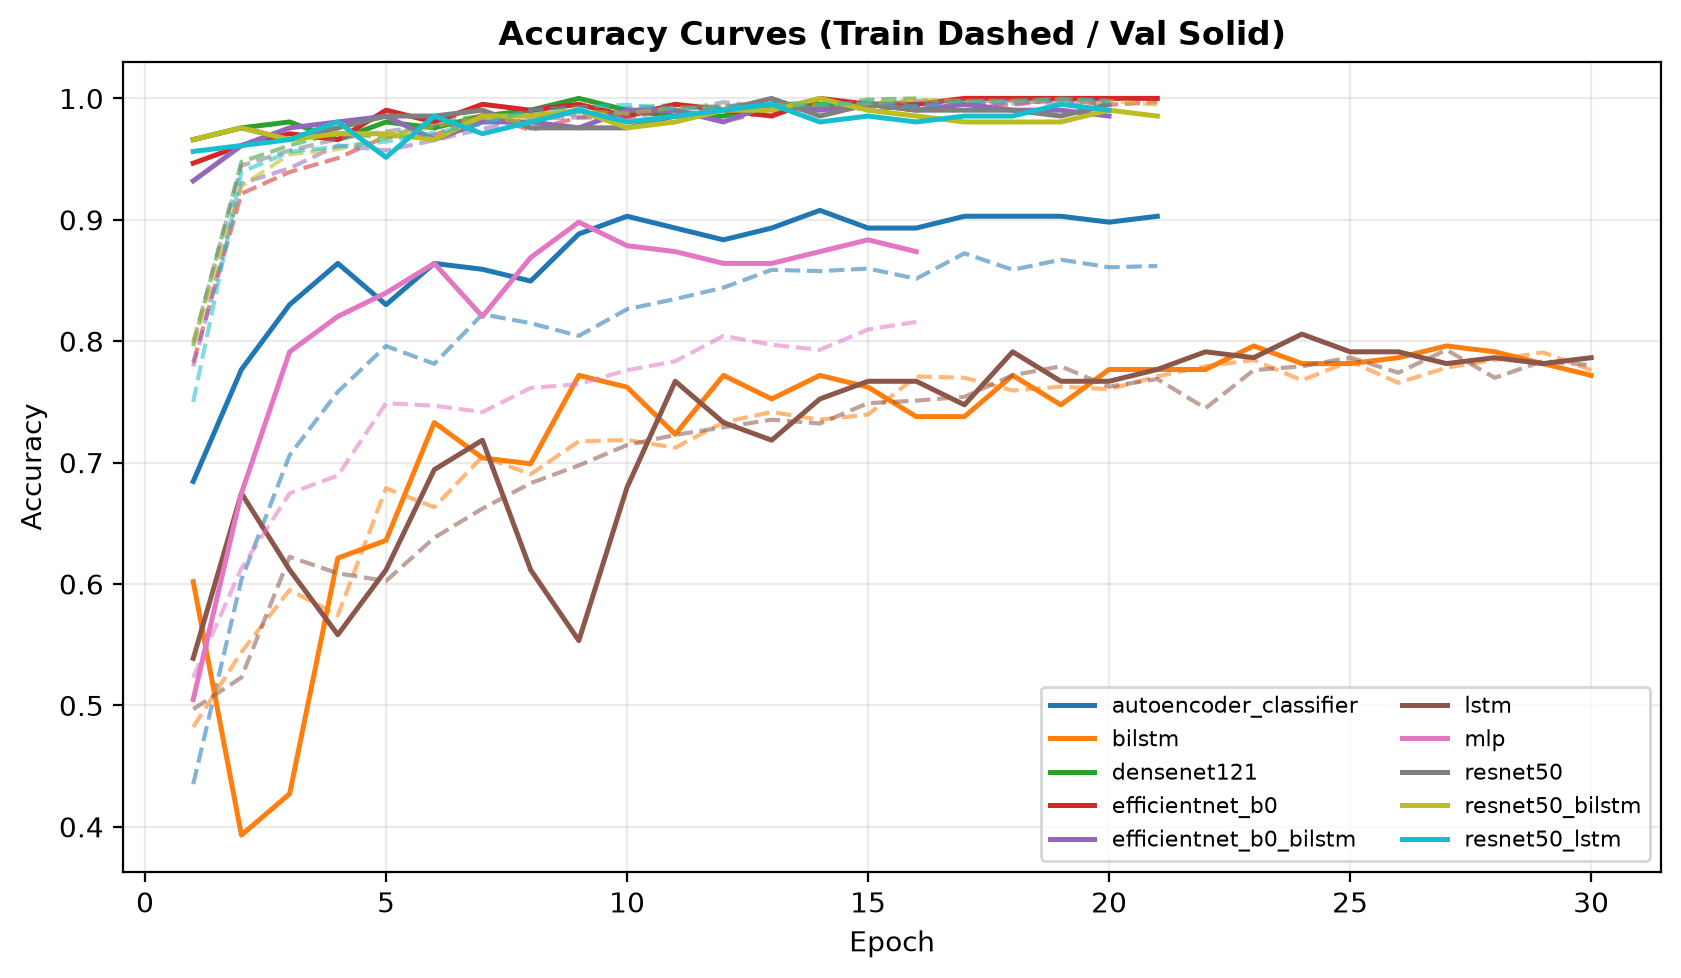

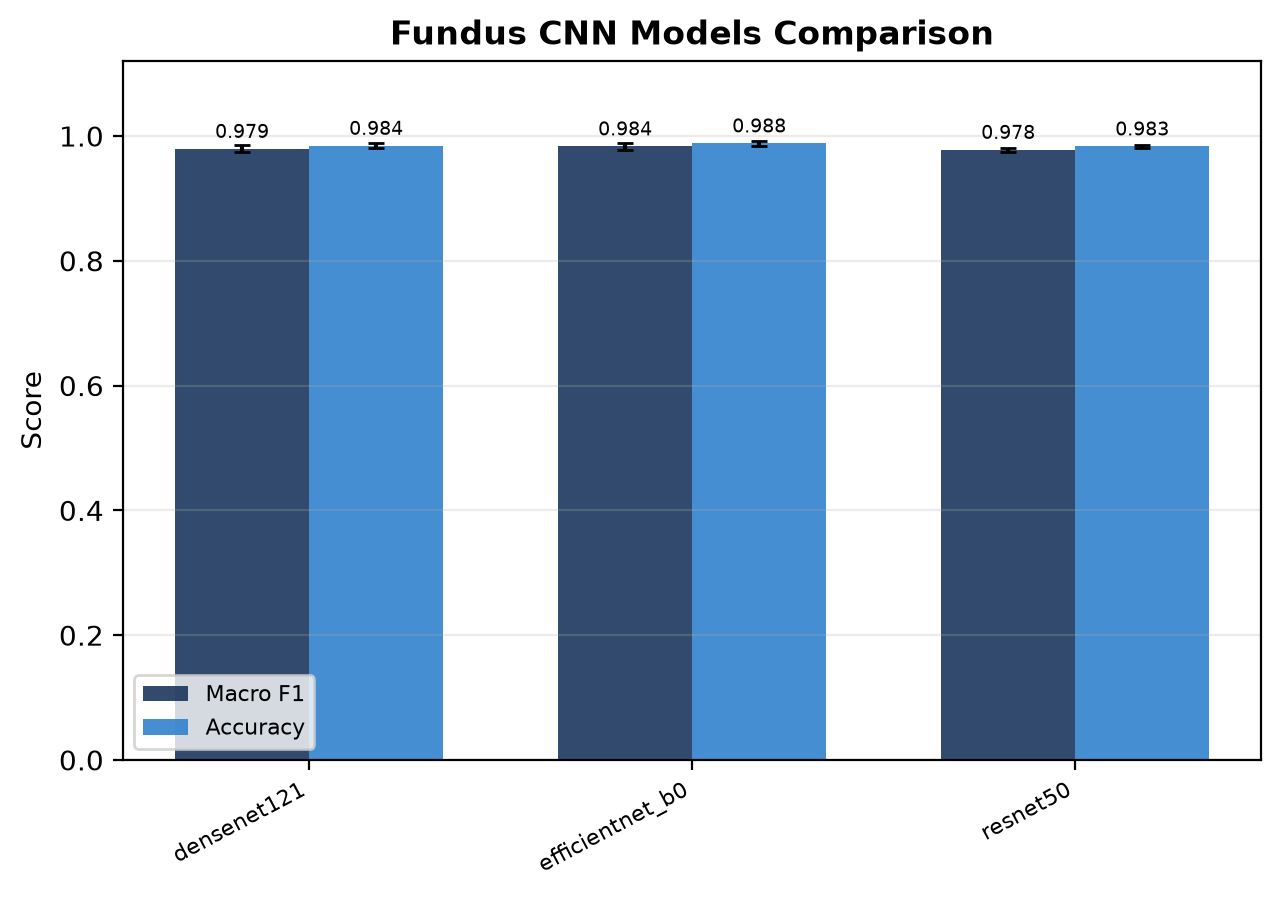

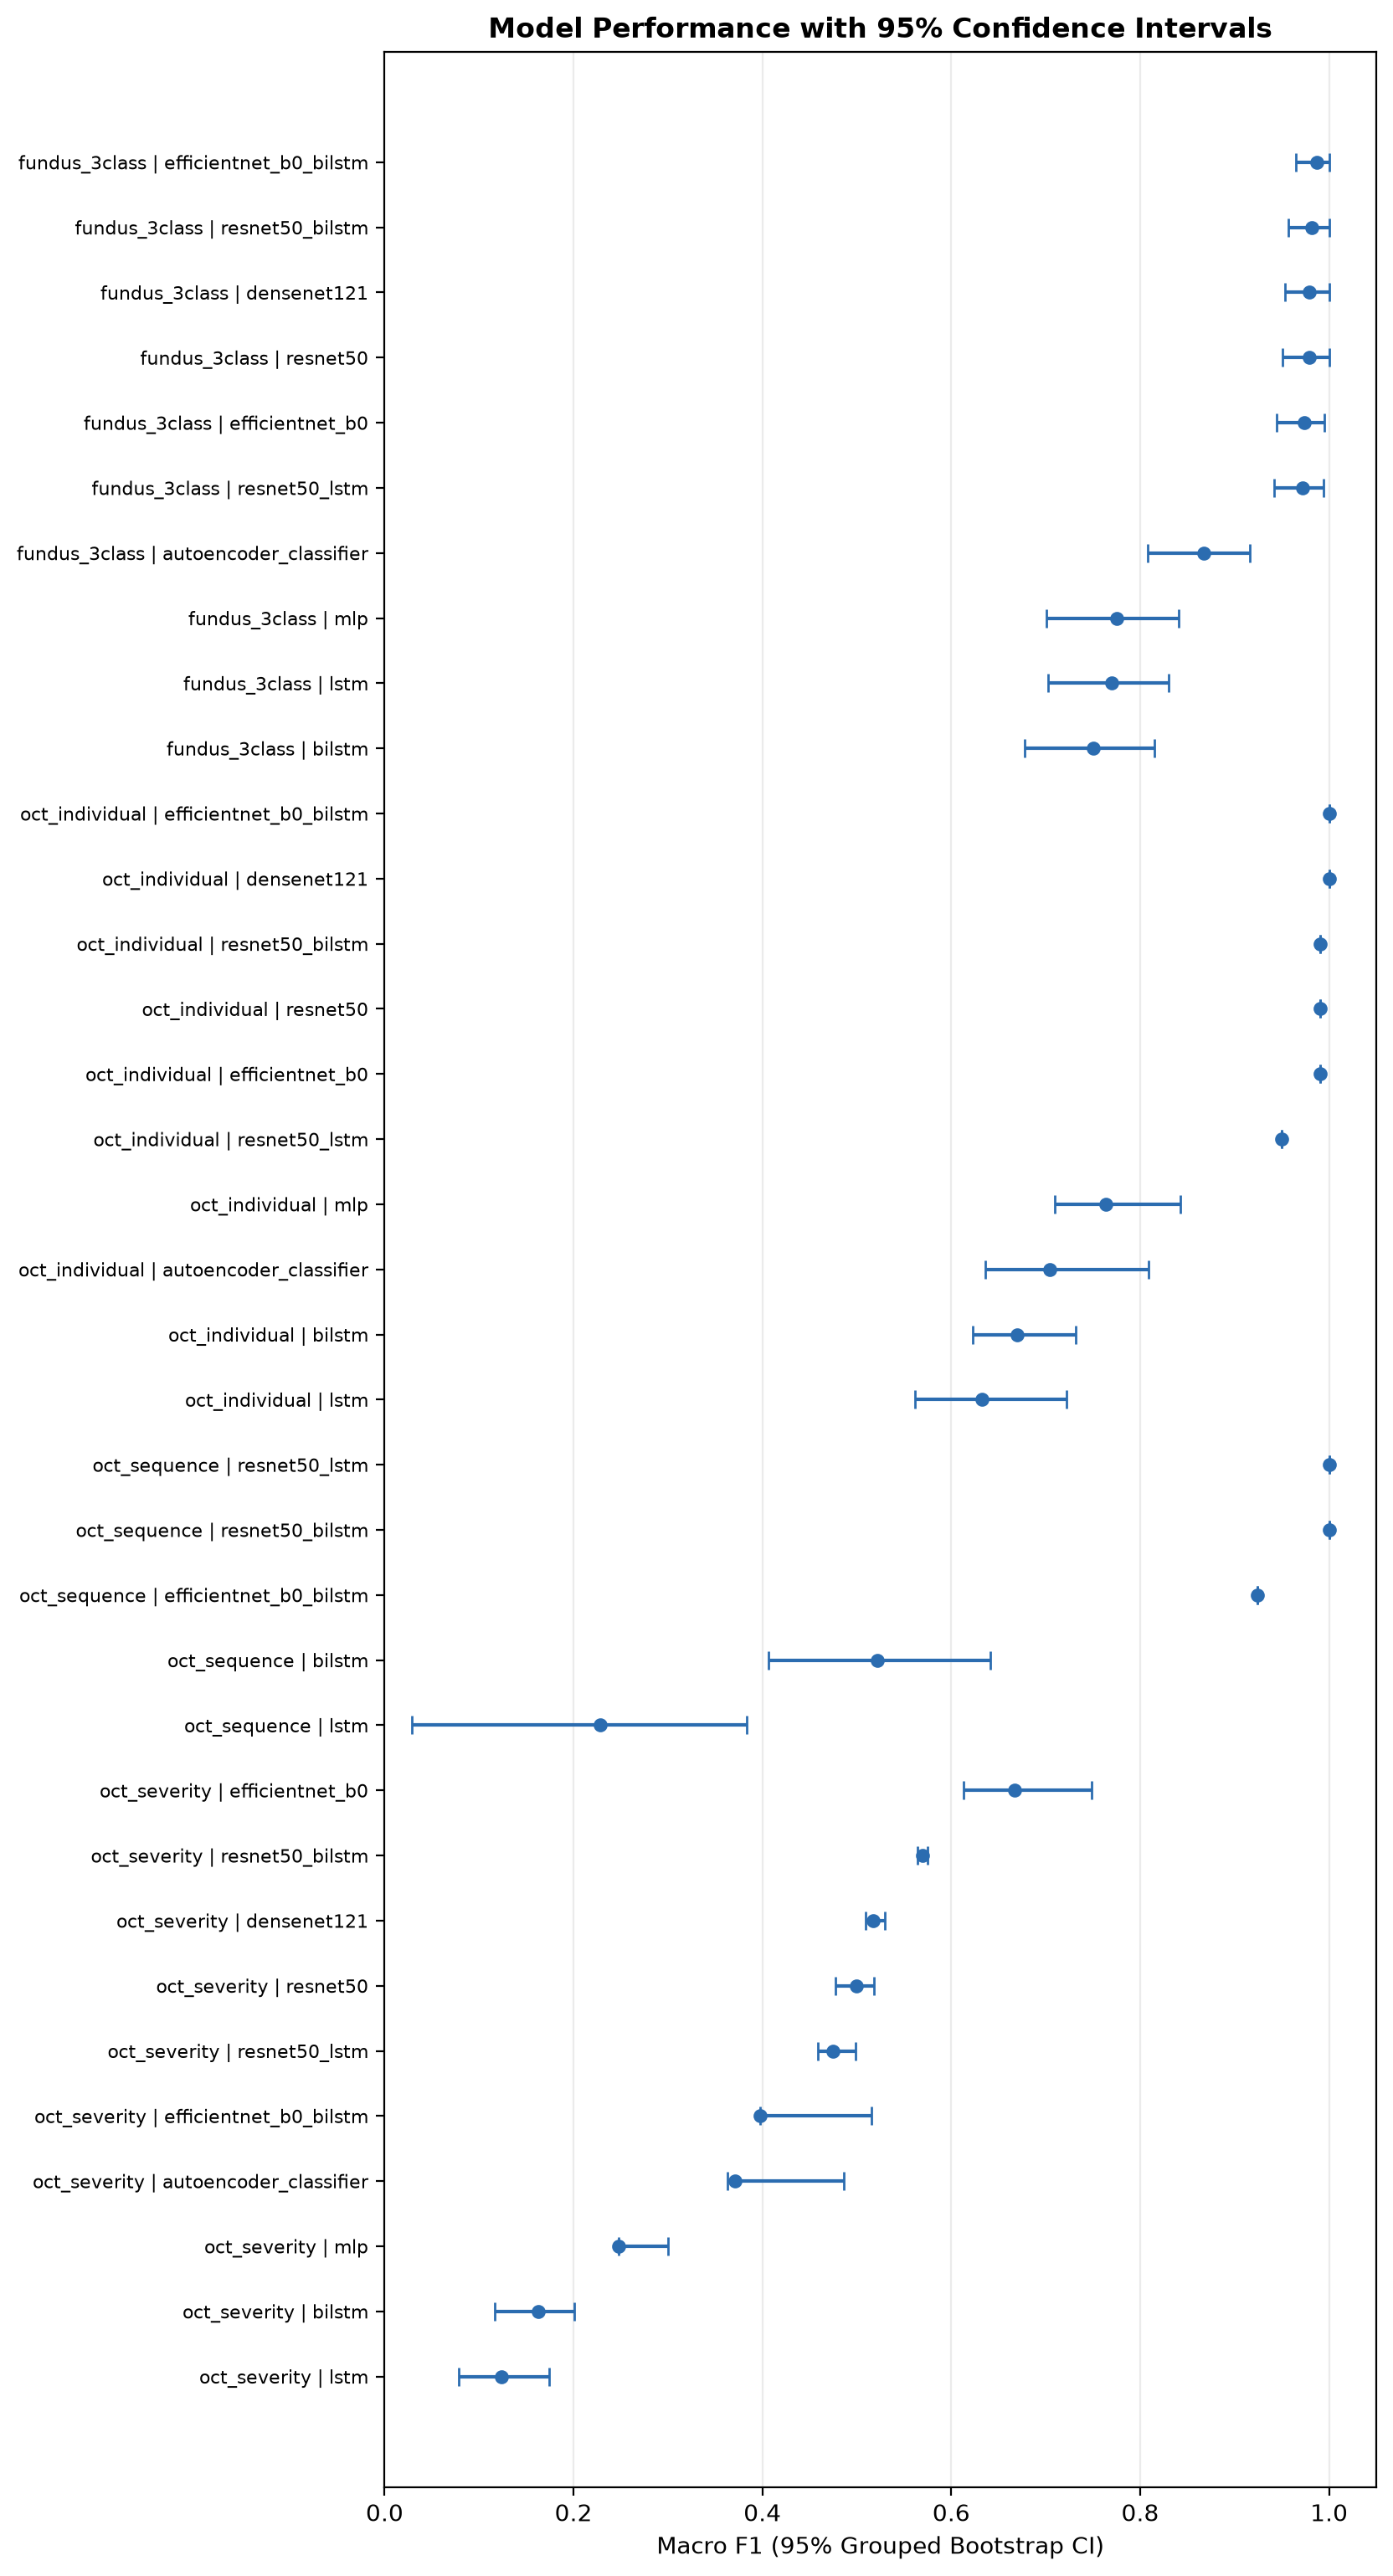

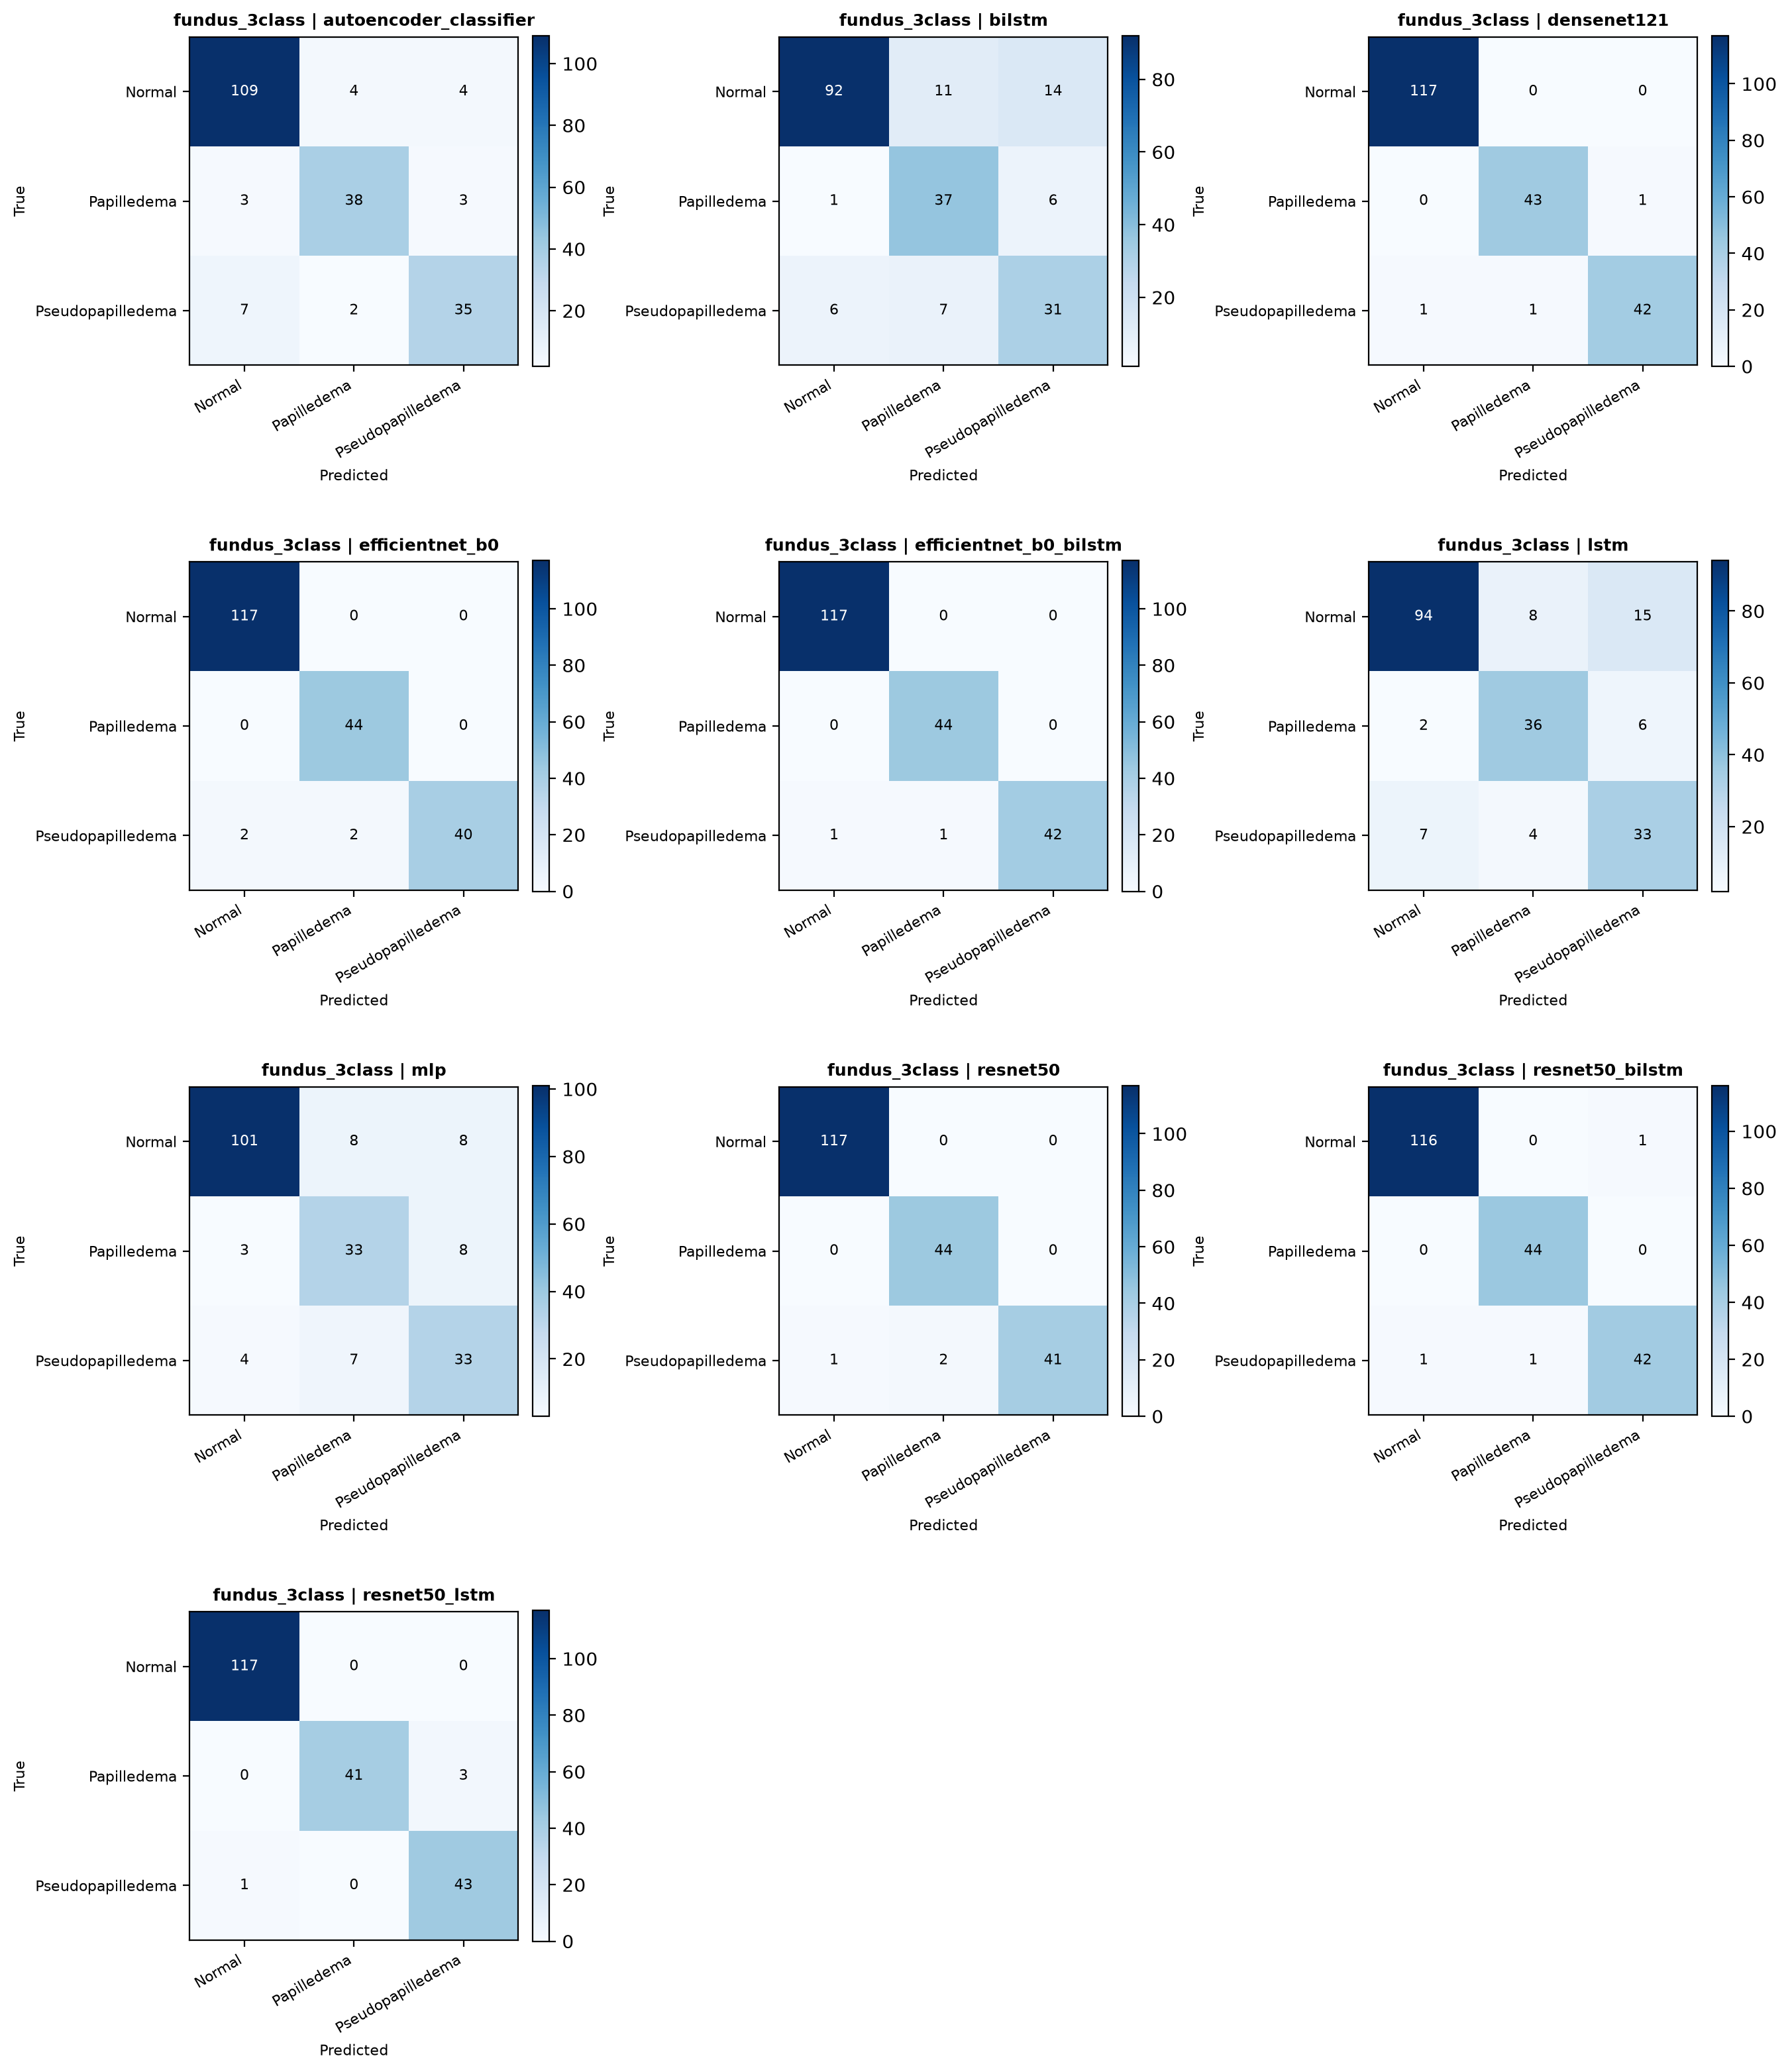

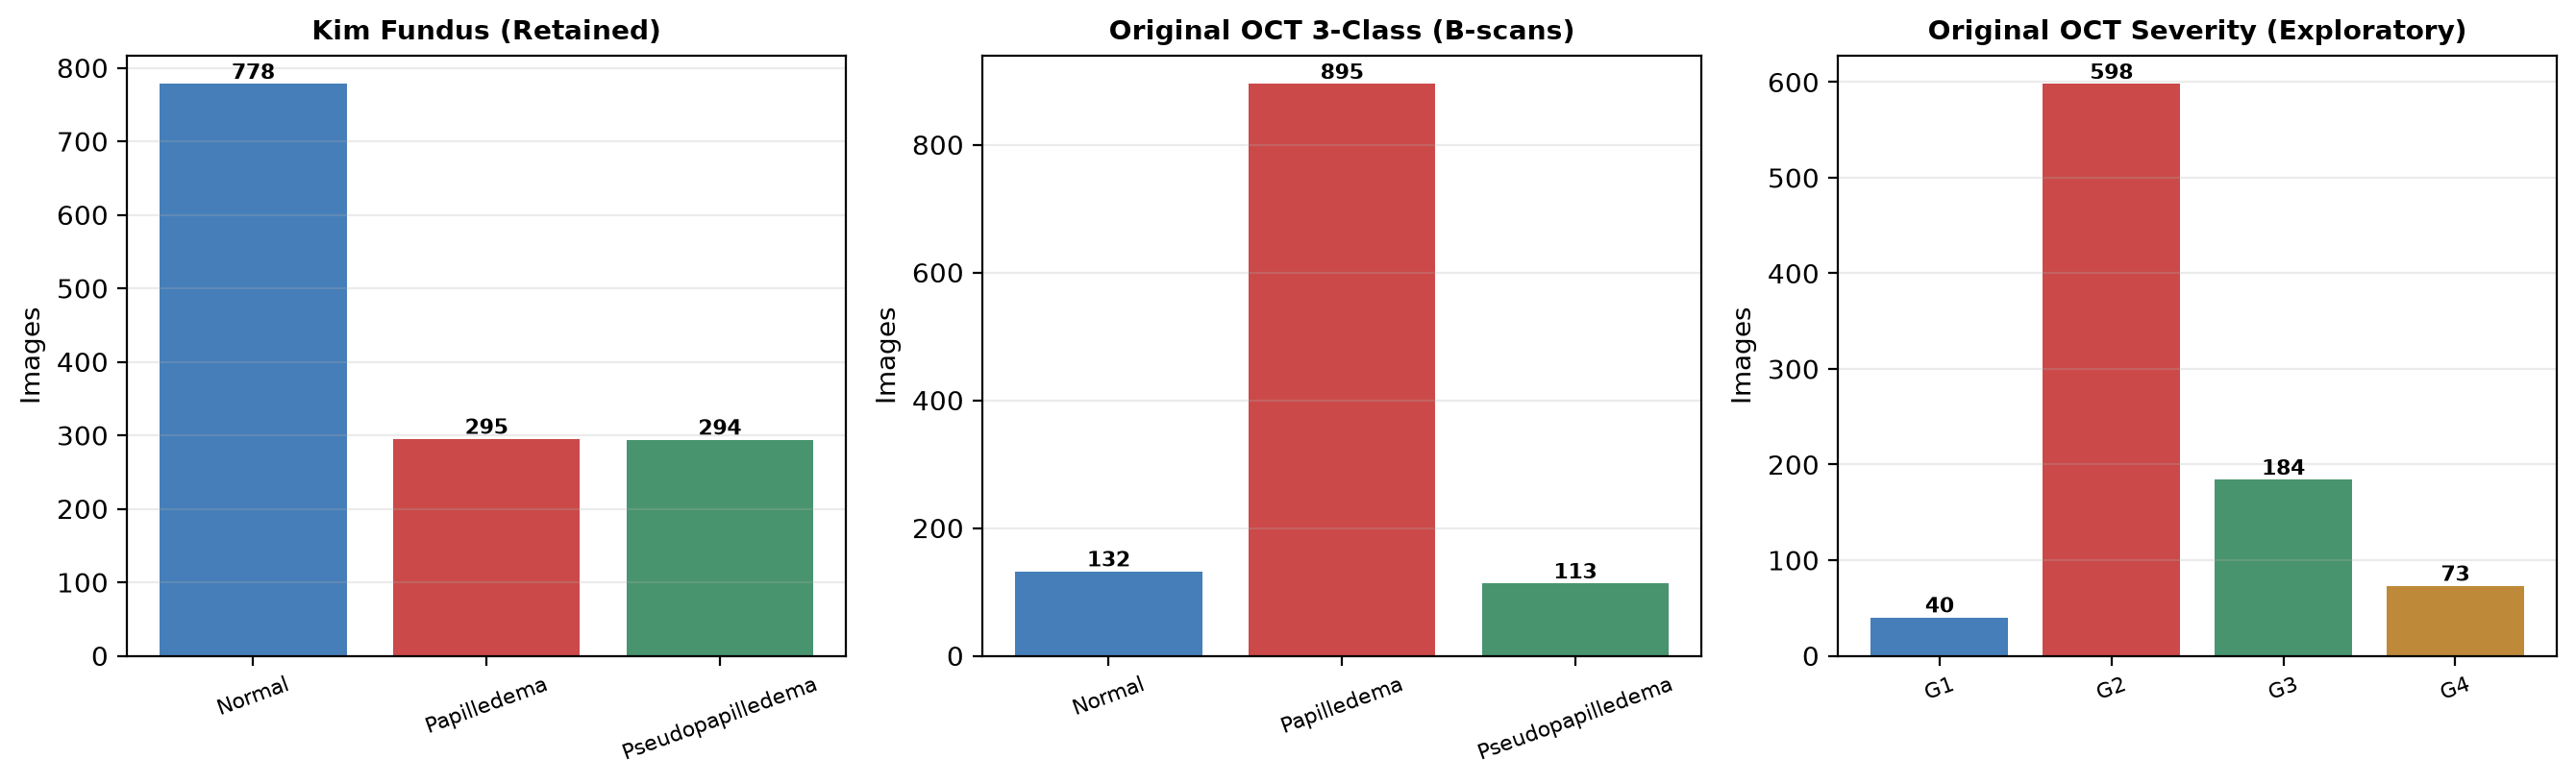

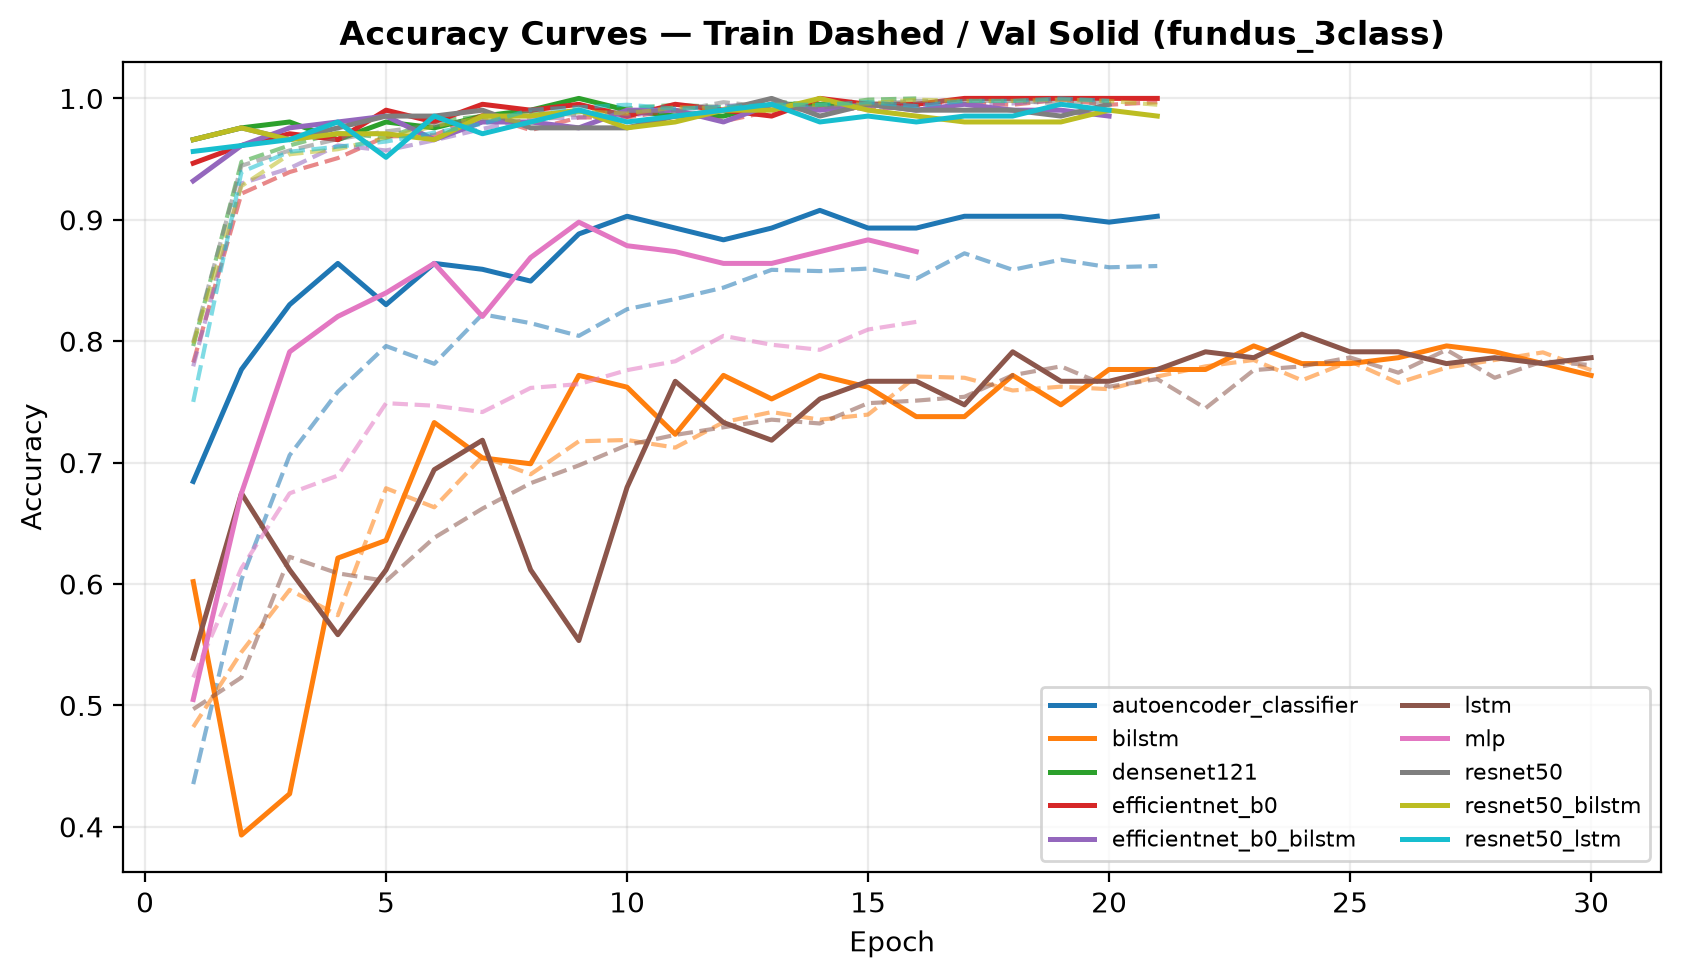

In [14]:
fig_dir = Path(cfg["paths"]["results_dir"]) / "figures"
figs = sorted(fig_dir.glob("*.png"))
print(f"Generated {len(figs)} figures in {fig_dir}:", [f.name for f in figs])
for f in figs[:6]:
    display(IPyImage(filename=str(f)))


## Section 15 — Error Analysis


In [15]:
pred_dir = Path(cfg["paths"]["results_dir"]) / "predictions"
err_files = sorted(pred_dir.glob("*_errors.csv"))
print(f"Error CSV files ({len(err_files)}):", [e.name for e in err_files[:10]])
if err_files:
    sample_err = pd.read_csv(err_files[0])
    print(f"Sample error table: {err_files[0].name} (rows={len(sample_err)})")
    display(sample_err.head(10))


Error CSV files (183): ['fundus_3class__autoencoder_classifier__seed123_errors.csv', 'fundus_3class__autoencoder_classifier__seed2024_errors.csv', 'fundus_3class__autoencoder_classifier__seed3407_errors.csv', 'fundus_3class__autoencoder_classifier__seed42__smoke_errors.csv', 'fundus_3class__autoencoder_classifier__seed42_errors.csv', 'fundus_3class__autoencoder_classifier__seed5678_errors.csv', 'fundus_3class__bilstm__seed123_errors.csv', 'fundus_3class__bilstm__seed2024_errors.csv', 'fundus_3class__bilstm__seed3407_errors.csv', 'fundus_3class__bilstm__seed42_errors.csv']
Sample error table: fundus_3class__autoencoder_classifier__seed123_errors.csv (rows=23)


,sample_id,image_path,group_id,true_idx,pred_idx,true_label,pred_label,correct,confidence,low_confidence,high_confidence_error,prob_Normal,prob_Papilledema,prob_Pseudopapilledema
0,fundus_Normal_101,data/raw/fundus/Normal/101.jpg,fundus_cluster_0003,0,1,Normal,Papilledema,False,0.918840,False,True,0.051159,0.918840,0.030001
1,fundus_Normal_238,data/raw/fundus/Normal/238.jpg,fundus_cluster_0151,0,2,Normal,Pseudopapilledema,False,0.865132,False,True,0.087563,0.047306,0.865132
2,fundus_Normal_294,data/raw/fundus/Normal/294.jpg,fundus_cluster_0213,0,2,Normal,Pseudopapilledema,False,0.864477,False,True,0.133156,0.002367,0.864477
3,fundus_Normal_683,data/raw/fundus/Normal/683.jpg,fundus_cluster_0644,0,1,Normal,Papilledema,False,0.805046,False,True,0.118035,0.805046,0.076919
4,fundus_Normal_734,data/raw/fundus/Normal/734.jpg,fundus_cluster_0701,0,2,Normal,Pseudopapilledema,False,0.560785,True,False,0.437593,0.001622,0.560785
5,fundus_Papilledema_167,data/raw/fundus/Papilledema/167.jpg,fundus_cluster_0844,1,2,Papilledema,Pseudopapilledema,False,0.790990,False,False,0.014601,0.194409,0.790990
6,fundus_Papilledema_169,data/raw/fundus/Papilledema/169.jpg,fundus_cluster_0844,1,2,Papilledema,Pseudopapilledema,False,0.652278,False,False,0.025765,0.321957,0.652278
7,fundus_Papilledema_174,data/raw/fundus/Papilledema/174.jpg,fundus_cluster_0850,1,2,Papilledema,Pseudopapilledema,False,0.808583,False,True,0.003994,0.187423,0.808583
8,fundus_Papilledema_212,data/raw/fundus/Papilledema/212.jpg,fundus_cluster_0890,1,2,Papilledema,Pseudopapilledema,False,0.662811,False,False,0.332957,0.004232,0.662811
9,fundus_Papilledema_237,data/raw/fundus/Papilledema/237.jpg,fundus_cluster_0917,1,2,Papilledema,Pseudopapilledema,False,0.487092,True,False,0.028897,0.484010,0.487092


## Section 16 — Final Research Summary


In [16]:
summary_path = Path(cfg["paths"]["results_dir"]) / "reports" / "final_research_summary.md"
if summary_path.exists():
    display(Markdown(summary_path.read_text(encoding="utf-8")))


# Final Research Summary

Fundus and OCT experimental tracks are evaluated and ranked strictly independently.

# Kim Fundus Classification Results

| Model | Seeds | Mean Macro F1 | Mean Accuracy | Mean Macro Recall | Params | Latency (ms) |
|---|---:|---:|---:|---:|---:|---:|
| efficientnet_b0 | 5 | 0.9835 | 0.9883 | 0.9818 | 4,011,391 | 2.54 |
| efficientnet_b0_bilstm | 5 | 0.9806 | 0.9854 | 0.9820 | 4,748,927 | 2.57 |
| densenet121 | 5 | 0.9795 | 0.9844 | 0.9786 | 6,956,931 | 3.25 |
| resnet50 | 5 | 0.9779 | 0.9834 | 0.9771 | 23,514,179 | 3.10 |
| resnet50_bilstm | 5 | 0.9779 | 0.9834 | 0.9761 | 24,446,019 | 3.09 |
| resnet50_lstm | 5 | 0.9684 | 0.9766 | 0.9684 | 24,247,747 | 3.02 |
| autoencoder_classifier | 5 | 0.8691 | 0.8937 | 0.8660 | 718,118 | 1.72 |
| mlp | 5 | 0.8018 | 0.8420 | 0.8056 | 233,231 | 2.02 |
| lstm | 5 | 0.7522 | 0.7776 | 0.7727 | 720,899 | 2.28 |
| bilstm | 5 | 0.7230 | 0.7522 | 0.7456 | 1,116,803 | 2.78 |

## Highlights
- Best by Macro F1: **efficientnet_b0** (0.9835)
- Best by Accuracy: **efficientnet_b0** (0.9883)
- Best by Macro Recall: **efficientnet_b0_bilstm** (0.9820)
- Fastest Inference: **autoencoder_classifier** (1.72 ms/sample)

## Caveats & Limitations
- Verified patient IDs are unavailable.
- Repeated and near-duplicate eye images are grouped into clusters kept intact across splits.
- Exact cross-class duplicates with conflicting labels are excluded from training/evaluation.
- Cannot be described as verified patient-independent evaluation.

---

# Original OCT 3-Class Results — Individual B-Scan (image mode)

| Model | Seeds | Mean Macro F1 | Mean Accuracy | Mean Macro Recall | Params | Latency (ms) |
|---|---:|---:|---:|---:|---:|---:|
| densenet121 | 5 | 0.9928 | 0.9978 | 0.9933 | 6,950,659 | 3.89 |
| efficientnet_b0 | 5 | 0.9903 | 0.9945 | 0.9833 | 4,010,815 | 3.25 |
| resnet50_bilstm | 5 | 0.9863 | 0.9934 | 0.9858 | 24,439,747 | 3.87 |
| efficientnet_b0_bilstm | 5 | 0.9807 | 0.9913 | 0.9820 | 4,748,351 | 3.29 |
| resnet50 | 5 | 0.9781 | 0.9902 | 0.9700 | 23,507,907 | 3.83 |
| resnet50_lstm | 5 | 0.9737 | 0.9869 | 0.9658 | 24,241,475 | 3.77 |
| autoencoder_classifier | 5 | 0.7317 | 0.8426 | 0.7933 | 717,252 | 2.33 |
| mlp | 5 | 0.7164 | 0.8678 | 0.6994 | 100,103 | 2.43 |
| bilstm | 5 | 0.6517 | 0.7836 | 0.7226 | 853,059 | 3.40 |
| lstm | 5 | 0.5585 | 0.5934 | 0.7346 | 457,155 | 2.89 |

## Highlights
- Best by Macro F1: **densenet121** (0.9928)
- Best by Accuracy: **densenet121** (0.9978)
- Best by Macro Recall: **densenet121** (0.9933)
- Fastest Inference: **autoencoder_classifier** (2.33 ms/sample)

# Original OCT 3-Class Results — Ordered Sequence (sequence mode)

| Model | Seeds | Mean Macro F1 | Mean Accuracy | Mean Macro Recall | Params | Latency (ms) |
|---|---:|---:|---:|---:|---:|---:|
| resnet50_bilstm | 5 | 0.9849 | 0.9913 | 0.9778 | 24,439,747 | 29.67 |
| efficientnet_b0_bilstm | 5 | 0.9142 | 0.9652 | 0.9111 | 4,748,351 | 24.80 |
| resnet50_lstm | 5 | 0.8608 | 0.9565 | 0.8889 | 24,241,475 | 28.83 |
| bilstm | 5 | 0.3385 | 0.7565 | 0.3815 | 853,059 | 18.58 |
| lstm | 5 | 0.2760 | 0.6870 | 0.3111 | 457,155 | 18.35 |

## Highlights
- Best by Macro F1: **resnet50_bilstm** (0.9849)
- Best by Accuracy: **resnet50_bilstm** (0.9913)
- Best by Macro Recall: **resnet50_bilstm** (0.9778)
- Fastest Inference: **lstm** (18.35 ms/sample)

## OCT Caveats & Limitations
- 1 IR/SLO non-B-scan image (heshama_001.jpg) is excluded, leaving 1,140 B-scans.
- Sequence IDs are inferred from filenames and visual continuity; never treated as verified patients.
- Normal (sabrenr) and Pseudopapilledema (heshama) each have only 1 inferred subject prefix (2 series); G1 and G4 each have 1 inferred prefix.
- No reliable clinical documentation validates Frisén G1-G4 severity grades; severity grading is strictly exploratory.
- Fabricated patient IDs and augmented folders are strictly excluded.

---

# Original OCT Exploratory Severity Grading (G1-G4)

| Model | Seeds | Mean Macro F1 | Mean Accuracy | Mean Macro Recall | Params | Latency (ms) |
|---|---:|---:|---:|---:|---:|---:|
| resnet50_lstm | 5 | 0.5274 | 0.7250 | 0.5157 | 24,241,604 | 3.80 |
| efficientnet_b0 | 5 | 0.5042 | 0.6875 | 0.5387 | 4,012,096 | 3.24 |
| resnet50_bilstm | 5 | 0.4789 | 0.7477 | 0.4945 | 24,440,004 | 4.13 |
| densenet121 | 5 | 0.4683 | 0.6625 | 0.4982 | 6,951,684 | 3.92 |
| resnet50 | 5 | 0.4495 | 0.6591 | 0.4270 | 23,509,956 | 3.87 |
| efficientnet_b0_bilstm | 5 | 0.3986 | 0.6773 | 0.4894 | 4,748,608 | 3.46 |
| autoencoder_classifier | 5 | 0.3643 | 0.5125 | 0.4427 | 717,381 | 2.54 |
| mlp | 5 | 0.2486 | 0.5170 | 0.3268 | 100,232 | 2.51 |
| lstm | 5 | 0.1808 | 0.4761 | 0.2099 | 457,284 | 2.93 |
| bilstm | 5 | 0.1476 | 0.3386 | 0.1888 | 853,316 | 3.41 |

## Highlights
- Best by Macro F1: **resnet50_lstm** (0.5274)
- Best by Accuracy: **resnet50_bilstm** (0.7477)
- Best by Macro Recall: **efficientnet_b0** (0.5387)
- Fastest Inference: **mlp** (2.51 ms/sample)

## Caveats & Limitations
- Strictly exploratory: no verified clinical documentation validating Frisén severity grades.
- G1 (hagerh) and G4 (mostafaa) each have only 1 inferred subject prefix; evaluation is NOT patient-independent.

---
## Statistical Findings
- Hypothesis tests recorded: 149
- Significant after Holm-Bonferroni (alpha=0.05): 87
- Reminder: Multi-seed tests assess training stochasticity on fixed splits, not patient-cohort generalization.